# Clean Floquet Circuit: Quantum Hardware Implementation

This notebook implements a clean Floquet quantum circuit and compares its ideal statevector dynamics with results obtained from real quantum hardware.

The experiment investigates the evolution of the local Z expectation value over 50 Floquet periods using 10 qubits on IBM Kingston.

## Requirements

The notebook requires:

- Python 3.14.6 (original experiment environment)
- Qiskit 2.6.1
- Qiskit IBM Runtime 0.52.1
- NumPy
- Matplotlib
- pylatexenc

An IBM Quantum account is required for backend access and hardware transpilation.

The original experiment results are included in the repository. The hardware submission function is disabled by default to prevent accidental execution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

In [2]:
# Connect to IBM Quantum using the saved account
service = QiskitRuntimeService(name="clean-floquet-research")

# Select the quantum computer
backend = service.backend("ibm_kingston")

# Verify the selected backend
print("Backend:", backend.name)
print("Physical qubits:", backend.num_qubits)
print("Operational:", backend.status().operational)

Backend: ibm_kingston
Physical qubits: 156
Operational: True


In [3]:
# Define the parameters for the clean Floquet circuit
numQubits = 10
maxPeriods = 50

rxAngle = np.pi / 4
ryAngle = np.pi / 3
interactionAngle = np.pi / 4

# Define the hardware execution parameters
shots = 512
measuredQubit = 0
optimizationLevel = 2

## Clean Floquet Circuit Construction

Each Floquet period consists of:
1. RX rotations on all qubits.
2. Nearest-neighbor RZZ interactions.
3. RY rotations on all qubits.
4. Nearest-neighbor RZZ interactions.

The Floquet period is repeated to construct circuits
spanning 0 to 50 periods. The first logical qubit is
measured to evaluate the evolution of its local Z
expectation value.

In [4]:
def createFloquetPeriod(numQubits, rxAngle, ryAngle, interactionAngle):
    circuit = QuantumCircuit(numQubits)

    # Apply RX rotations to all qubits
    for qubit in range(numQubits):
        circuit.rx(rxAngle, qubit)

    # Apply ZZ interactions to even-indexed pairs
    for qubit in range(0, numQubits - 1, 2):
        circuit.rzz(interactionAngle, qubit, qubit + 1)

    # Apply ZZ interactions to odd-indexed pairs
    for qubit in range(1, numQubits - 1, 2):
        circuit.rzz(interactionAngle, qubit, qubit + 1)

    # Apply RY rotations to all qubits
    for qubit in range(numQubits):
        circuit.ry(ryAngle, qubit)

    # Apply another round of even-indexed ZZ interactions
    for qubit in range(0, numQubits - 1, 2):
        circuit.rzz(interactionAngle, qubit, qubit + 1)

    # Apply another round of odd-indexed ZZ interactions
    for qubit in range(1, numQubits - 1, 2):
        circuit.rzz(interactionAngle, qubit, qubit + 1)

    return circuit

Number of qubits: 10
Circuit depth: 6
Total gates: 38
Gate counts: OrderedDict({'rzz': 18, 'rx': 10, 'ry': 10})


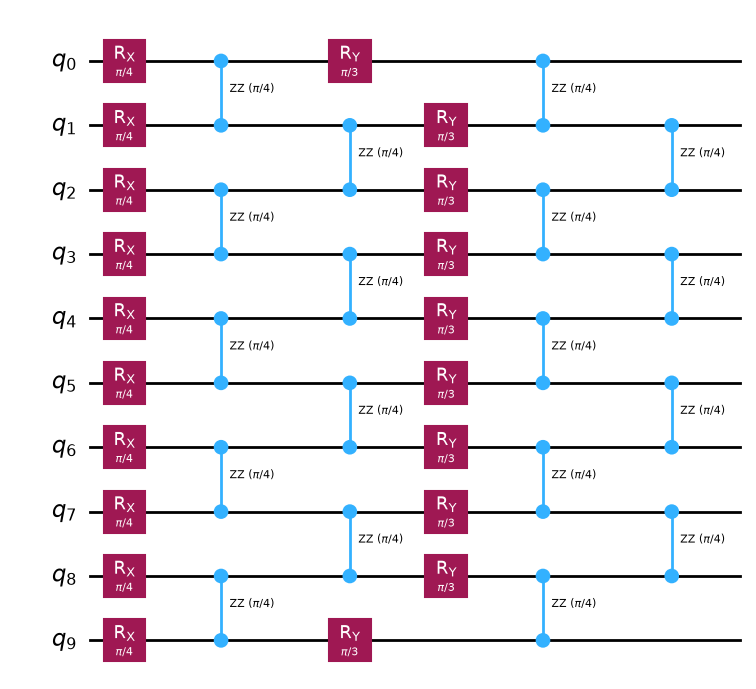

In [5]:
# Create one complete Floquet period
floquetPeriod = createFloquetPeriod(
    numQubits,
    rxAngle,
    ryAngle,
    interactionAngle
)

# Verify the circuit structure
print("Number of qubits:", floquetPeriod.num_qubits)
print("Circuit depth:", floquetPeriod.depth())
print("Total gates:", floquetPeriod.size())
print("Gate counts:", floquetPeriod.count_ops())

# Display the circuit
display(floquetPeriod.draw(output="mpl"))

In [6]:
def createFloquetCircuit(floquetPeriod, numPeriods):
    numQubits = floquetPeriod.num_qubits
    circuit = QuantumCircuit(numQubits)

    # Repeat the same Floquet period
    for period in range(numPeriods):
        circuit.compose(floquetPeriod, inplace=True)

    return circuit

In [7]:
def createHardwareCircuit(floquetPeriod, numPeriods, measuredQubit):
    # Create the circuit with the specified number of periods
    circuit = createFloquetCircuit(floquetPeriod, numPeriods)

    # Create a classical register to store the measurement
    from qiskit import ClassicalRegister
    measurementRegister = ClassicalRegister(1, "meas")
    circuit.add_register(measurementRegister)

    # Measure the selected qubit
    circuit.measure(measuredQubit, measurementRegister[0])

    return circuit

In [8]:
# Define the range of Floquet periods
periods = list(range(maxPeriods + 1))

# Create a hardware circuit for each number of periods
hardwareCircuits = []

for numPeriods in periods:
    circuit = createHardwareCircuit(
        floquetPeriod,
        numPeriods,
        measuredQubit
    )

    circuit.name = f"clean_floquet_{numPeriods}_periods"
    hardwareCircuits.append(circuit)

# Verify the generated circuits
print("Total circuits:", len(hardwareCircuits))
print("Shots per circuit:", shots)
print("Total shots:", len(hardwareCircuits) * shots)

Total circuits: 51
Shots per circuit: 512
Total shots: 26112


## Physical Qubit Selection

A connected chain of 10 physical qubits was selected on
IBM Kingston by minimizing the cumulative calibrated CZ
gate error across adjacent qubits.

The selected layout had an average CZ gate error of
approximately 0.133%.

The physical layout is fixed below to preserve the
configuration used in the completed hardware experiment.
Calibration errors reflect the original selection and
may change over time.

In [9]:
# Physical qubit layout selected for the hardware experiment
physicalLayout = [67, 68, 69, 70, 71, 72, 73, 79, 93, 92]

# CZ calibration errors recorded during physical qubit selection
selectedCZErrors = [
    0.001105,
    0.001477,
    0.001645,
    0.001231,
    0.001323,
    0.001259,
    0.001126,
    0.001269,
    0.001524
]

# Original calibration error statistics
totalCZError = 0.011957791584956828
averageCZError = totalCZError / (numQubits - 1)

print("Selected physical qubits:", physicalLayout)
print("Number of selected qubits:", len(physicalLayout))
print("Total CZ error score:", totalCZError)
print("Average CZ error:", averageCZError)

Selected physical qubits: [67, 68, 69, 70, 71, 72, 73, 79, 93, 92]
Number of selected qubits: 10
Total CZ error score: 0.011957791584956828
Average CZ error: 0.0013286435094396476


## Hardware Transpilation

Optimization levels 1, 2, and 3 were evaluated using
circuits containing 1, 10, and 50 Floquet periods.

Optimization level 2 was selected because it reduced
circuit depth and total gate operations while preserving
the physical qubit layout and CZ gate count.

For the 50-period circuit:
- Circuit depth decreased from 2,005 to 1,705 (14.96%).
- Total operations decreased from 11,826 to 9,830 (16.88%).
- The CZ gate count remained unchanged at 1,800.

Optimization level 3 provided no additional improvement
in circuit depth or CZ gate count.

In [10]:
# Configure the transpiler for IBM Kingston
passManager = generate_preset_pass_manager(
    backend=backend,
    optimization_level=optimizationLevel,
    initial_layout=physicalLayout,
    seed_transpiler=42,
    approximation_degree=1.0
)

print("Backend:", backend.name)
print("Optimization level:", optimizationLevel)
print("Physical layout:", physicalLayout)

Backend: ibm_kingston
Optimization level: 2
Physical layout: [67, 68, 69, 70, 71, 72, 73, 79, 93, 92]


In [11]:
# Transpile all circuits using optimization level 2
transpiledCircuits = passManager.run(hardwareCircuits)

# Store transpiled circuit statistics
transpiledDepths = [
    circuit.depth()
    for circuit in transpiledCircuits
]

transpiledOperations = [
    circuit.size()
    for circuit in transpiledCircuits
]

czCounts = [
    circuit.count_ops().get("cz", 0)
    for circuit in transpiledCircuits
]

print("Optimization level:", optimizationLevel)
print("Total transpiled circuits:", len(transpiledCircuits))

# Display circuit statistics for selected periods
for numPeriods in [0, 1, 5, 10, 25, 50]:
    print(
        f"Periods: {numPeriods:2d} | "
        f"Depth: {transpiledDepths[numPeriods]:4d} | "
        f"Operations: {transpiledOperations[numPeriods]:5d} | "
        f"CZ gates: {czCounts[numPeriods]:4d}"
    )

Optimization level: 2
Total transpiled circuits: 51
Periods:  0 | Depth:    1 | Operations:     1 | CZ gates:    0
Periods:  1 | Depth:   39 | Operations:   226 | CZ gates:   36
Periods:  5 | Depth:  175 | Operations:  1010 | CZ gates:  180
Periods: 10 | Depth:  345 | Operations:  1990 | CZ gates:  360
Periods: 25 | Depth:  855 | Operations:  4930 | CZ gates:  900
Periods: 50 | Depth: 1705 | Operations:  9830 | CZ gates: 1800


## Hardware Compatibility Verification

All transpiled circuits are verified to ensure that:

- Every instruction is supported by the target hardware.
- The selected physical qubit layout is preserved.
- Each circuit contains exactly one measurement.
- The measurement targets the intended physical qubit.

In [12]:
# Store any issues found during verification
verificationErrors = []

for numPeriods, circuit in zip(periods, transpiledCircuits):

    # Verify the final physical layout
    finalLayout = circuit.layout.final_index_layout()

    if finalLayout != physicalLayout:
        verificationErrors.append(
            (numPeriods, "Physical layout changed")
        )

    # Verify that exactly one measurement exists
    if circuit.count_ops().get("measure", 0) != 1:
        verificationErrors.append(
            (numPeriods, "Incorrect measurement count")
        )

    # Verify each hardware instruction
    for instruction in circuit.data:
        gateName = instruction.operation.name

        physicalQubits = tuple(
            circuit.find_bit(qubit).index
            for qubit in instruction.qubits
        )

        if not backend.target.instruction_supported(
            operation_name=gateName,
            qargs=physicalQubits
        ):
            verificationErrors.append(
                (numPeriods, gateName, physicalQubits)
            )

        # Verify the measured physical qubit
        if gateName == "measure":
            if physicalQubits[0] != physicalLayout[measuredQubit]:
                verificationErrors.append(
                    (numPeriods, "Incorrect measurement mapping")
                )

print("Total circuits checked:", len(transpiledCircuits))
print("Verification errors:", len(verificationErrors))
print("All circuits verified:", len(verificationErrors) == 0)

if verificationErrors:
    print("Errors:", verificationErrors)

Total circuits checked: 51
Verification errors: 0
All circuits verified: True


In [13]:
# Convert the hardware circuit back to a compact 10-qubit circuit
# while preserving its transpiled gate operations
def createCompactCircuit(transpiledCircuit, physicalLayout):

    compactCircuit = QuantumCircuit(len(physicalLayout))

    # Map physical qubit indices back to logical qubit indices
    physicalToLogical = {
        physicalQubit: logicalQubit
        for logicalQubit, physicalQubit in enumerate(physicalLayout)
    }

    # Copy the circuit's global phase
    compactCircuit.global_phase = transpiledCircuit.global_phase

    for instruction in transpiledCircuit.data:

        gateName = instruction.operation.name

        # Skip measurement for statevector simulation
        if gateName == "measure":
            continue

        # Identify the physical qubits used by the instruction
        physicalQubits = [
            transpiledCircuit.find_bit(qubit).index
            for qubit in instruction.qubits
        ]

        # Ensure no unexpected physical qubits are being used
        if any(
            qubit not in physicalToLogical
            for qubit in physicalQubits
        ):
            raise ValueError(
                f"Unexpected physical qubits: {physicalQubits}"
            )

        # Convert physical indices back to logical indices
        logicalQubits = [
            physicalToLogical[qubit]
            for qubit in physicalQubits
        ]

        # Add the same native gate to the compact circuit
        compactCircuit.append(
            instruction.operation,
            logicalQubits
        )

    return compactCircuit

In [14]:
# Define the Z observable for logical qubit 0
pauliZ = SparsePauliOp(
    "I" * (numQubits - 1) + "Z"
)

# Store numerical verification results
stateFidelities = []
expectationDifferences = []
idealExpectationValues = []
transpiledExpectationValues = []

for numPeriods in periods:

    # Create the original circuit without measurements
    originalCircuit = createFloquetCircuit(
        floquetPeriod,
        numPeriods
    )

    # Create the compact version of the transpiled circuit
    compactCircuit = createCompactCircuit(
        transpiledCircuits[numPeriods],
        physicalLayout
    )

    # Simulate both circuits
    originalState = Statevector.from_instruction(
        originalCircuit
    )

    transpiledState = Statevector.from_instruction(
        compactCircuit
    )

    # Calculate state fidelity
    fidelity = float(
        abs(
            np.vdot(
                originalState.data,
                transpiledState.data
            )
        ) ** 2
    )

    # Calculate the Z expectation values
    originalZ = float(
        originalState.expectation_value(pauliZ).real
    )

    transpiledZ = float(
        transpiledState.expectation_value(pauliZ).real
    )

    # Calculate the difference between expectation values
    difference = abs(originalZ - transpiledZ)

    # Store the results
    stateFidelities.append(fidelity)
    expectationDifferences.append(difference)
    idealExpectationValues.append(originalZ)
    transpiledExpectationValues.append(transpiledZ)

    # Display results for selected periods
    if numPeriods in [0, 1, 5, 10, 25, 50]:
        print(
            f"Periods: {numPeriods:2d} | "
            f"Fidelity: {fidelity:.12f} | "
            f"Original Z: {originalZ:.8f} | "
            f"Transpiled Z: {transpiledZ:.8f} | "
            f"Difference: {difference:.2e}"
        )

# Summarize numerical verification
tolerance = 1e-8

numericalVerificationPassed = (
    len(stateFidelities) == len(periods)
    and np.allclose(
        stateFidelities, 1.0,
        atol=tolerance, rtol=0
    )
    and max(expectationDifferences) < tolerance
)

print("\nTotal circuits checked:", len(stateFidelities))
print("Minimum state fidelity:", min(stateFidelities))
print("Maximum expectation difference:", max(expectationDifferences))
print("Numerical verification passed:", numericalVerificationPassed)

Periods:  0 | Fidelity: 1.000000000000 | Original Z: 1.00000000 | Transpiled Z: 1.00000000 | Difference: 0.00e+00
Periods:  1 | Fidelity: 1.000000000000 | Original Z: 0.04736717 | Transpiled Z: 0.04736717 | Difference: 7.01e-16
Periods:  5 | Fidelity: 1.000000000000 | Original Z: 0.03434483 | Transpiled Z: 0.03434483 | Difference: 7.84e-16
Periods: 10 | Fidelity: 1.000000000000 | Original Z: 0.04664464 | Transpiled Z: 0.04664464 | Difference: 1.67e-16
Periods: 25 | Fidelity: 1.000000000000 | Original Z: 0.00648504 | Transpiled Z: 0.00648504 | Difference: 1.41e-15
Periods: 50 | Fidelity: 1.000000000000 | Original Z: 0.05004075 | Transpiled Z: 0.05004075 | Difference: 4.61e-15

Total circuits checked: 51
Minimum state fidelity: 0.9999999999999989
Maximum expectation difference: 5.731526364627371e-15
Numerical verification passed: True


## Quantum Hardware Execution

The experiment was executed on IBM Kingston using
SamplerV2 with 512 shots per circuit across 51 circuits.

A total of 26,112 measurement shots were collected.

The submission function is disabled by default to
prevent accidental hardware execution. The existing
job information and experimental results are saved
in separate JSON files.

In [15]:
from pathlib import Path
from datetime import datetime, timezone

# Submit the experiment only when explicitly requested
def submitHardwareExperiment():

    assert len(transpiledCircuits) == 51
    assert len(verificationErrors) == 0
    assert numericalVerificationPassed
    assert optimizationLevel == 2

    jobFile = Path("clean_floquet_hardware_jobs.json")

    # Prevent duplicate hardware submissions
    if jobFile.exists():
        raise RuntimeError(
            "A hardware job has already been recorded. "
            "Retrieve the existing job instead."
        )

    # Initialize the sampler and submit the circuits
    sampler = SamplerV2(mode=backend)

    job = sampler.run(
        transpiledCircuits,
        shots=shots
    )

    print("Job ID:", job.job_id())

    # Record the experiment configuration
    jobInfo = {
        "job_id": job.job_id(),
        "backend": backend.name,
        "submitted_at": datetime.now(timezone.utc).isoformat(),
        "num_qubits": numQubits,
        "physical_layout": physicalLayout,
        "measured_qubit": measuredQubit,
        "shots": shots,
        "periods": periods,
        "optimization_level": optimizationLevel,
        "seed_transpiler": 42,
        "rx_angle": float(rxAngle),
        "ry_angle": float(ryAngle),
        "interaction_angle": float(interactionAngle),
        "circuit_depths": transpiledDepths,
        "circuit_operations": transpiledOperations,
        "cz_counts": czCounts
    }

    # Save the job information
    with open(jobFile, "w") as file:
        json.dump(jobInfo, file, indent=4)

    print("Hardware experiment submitted successfully!")
    print("Job information saved to:", jobFile)

    return job


# Uncomment only when intentionally submitting a new experiment
# job = submitHardwareExperiment()

## Hardware Results

The measurement results from the completed IBM Kingston
experiment are loaded from the saved JSON file.

The file contains the experimental configuration, raw
measurement counts, hardware and ideal Z expectation
values, statistical standard errors, and circuit statistics.

Using saved results allows the experimental data to be
analyzed without submitting additional hardware jobs or
accessing the original IBM Quantum job.

In [16]:
# Load the saved hardware experiment results
resultsFile = Path("clean_floquet_hardware_results.json")

with open(resultsFile, "r") as file:
    resultsData = json.load(file)

# Extract experiment metadata and measurement results
jobInfo = resultsData["experiment"]
hardwareResults = resultsData["results"]

# Extract values for plotting and analysis
periods = [
    result["periods"]
    for result in hardwareResults
]

hardwareExpectationValues = [
    result["hardware_expectation_z"]
    for result in hardwareResults
]

hardwareStandardErrors = [
    result["standard_error"]
    for result in hardwareResults
]

savedIdealExpectationValues = [
    result["ideal_expectation_z"]
    for result in hardwareResults
]

# Verify the simulation against the saved ideal results
assert np.allclose(
    idealExpectationValues,
    savedIdealExpectationValues,
    atol=1e-8,
    rtol=0
)

print("Ideal simulation matches saved results!")

# Verify the saved results
assert len(hardwareResults) == 51
assert periods == list(range(maxPeriods + 1))
assert all(result["shots"] == shots for result in hardwareResults)
assert all(
    sum(result["counts"].values()) == shots
    for result in hardwareResults
)

print("Backend:", jobInfo["backend"])
print("Job ID:", jobInfo["job_id"])
print("Total circuits:", len(hardwareResults))
print("Shots per circuit:", jobInfo["shots"])
print("Total shots:", sum(result["shots"] for result in hardwareResults))
print("Hardware results loaded successfully!")

Ideal simulation matches saved results!
Backend: ibm_kingston
Job ID: dc2p5pdhdvas73bmkekg
Total circuits: 51
Shots per circuit: 512
Total shots: 26112
Hardware results loaded successfully!


In [17]:
# Calculate expectation values and standard errors from saved counts
hardwareExpectationValues = []
hardwareStandardErrors = []

for result in hardwareResults:
    counts = result["counts"]

    zeroCounts = counts.get("0", 0)
    oneCounts = counts.get("1", 0)
    totalCounts = zeroCounts + oneCounts

    assert totalCounts == shots

    # Calculate the Z expectation value
    expectationZ = (zeroCounts - oneCounts) / totalCounts

    # Calculate the statistical standard error
    standardError = np.sqrt(
        (1 - expectationZ**2) / totalCounts
    )

    hardwareExpectationValues.append(expectationZ)
    hardwareStandardErrors.append(standardError)

    # Verify against the original saved results
    assert np.isclose(
        expectationZ, result["hardware_expectation_z"]
    )
    assert np.isclose(
        standardError, result["standard_error"]
    )

print("All hardware expectation values verified successfully!")
print("All statistical standard errors verified successfully!")

All hardware expectation values verified successfully!
All statistical standard errors verified successfully!


## Experimental Results and Analysis

The hardware measurement results are compared against
the ideal statevector simulation.

Error bars represent one estimated statistical standard
error due to finite-shot sampling. They do not account
for systematic hardware errors.

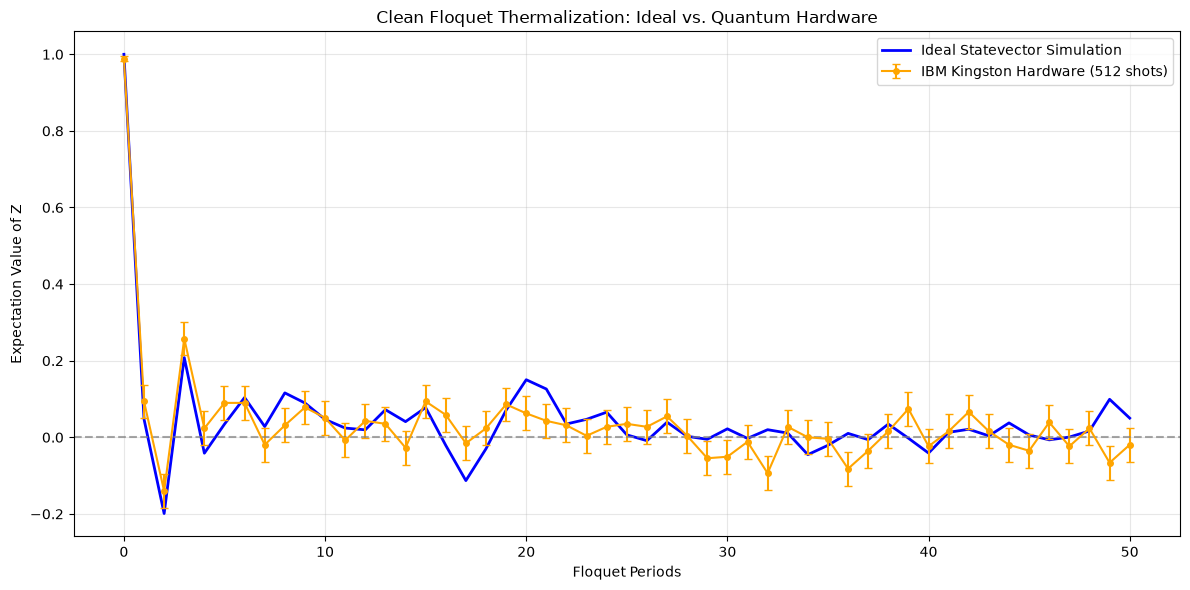

In [18]:
plt.figure(figsize=(12, 6))

# Plot the ideal statevector simulation
plt.plot(
    periods,
    idealExpectationValues,
    color="blue",
    linewidth=2,
    label="Ideal Statevector Simulation"
)

# Plot hardware measurements with error bars
plt.errorbar(
    periods,
    hardwareExpectationValues,
    yerr=hardwareStandardErrors,
    color="orange",
    marker="o",
    markersize=4,
    linewidth=1.5,
    capsize=3,
    label="IBM Kingston Hardware (512 shots)"
)

# Add a reference line at zero
plt.axhline(
    0,
    color="gray",
    linestyle="--",
    alpha=0.7
)

plt.xlabel("Floquet Periods")
plt.ylabel("Expectation Value of Z")
plt.title("Clean Floquet Thermalization: Ideal vs. Quantum Hardware")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the final experimental plot
plt.savefig(
    "clean_floquet_hardware_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
# Convert expectation values into NumPy arrays
idealValues = np.array(idealExpectationValues)
hardwareValues = np.array(hardwareExpectationValues)

# Calculate experimental error metrics
absoluteErrors = np.abs(hardwareValues - idealValues)

mae = np.mean(absoluteErrors)

rmse = np.sqrt(
    np.mean((hardwareValues - idealValues) ** 2)
)

maxError = np.max(absoluteErrors)

print("Clean Floquet Hardware Experiment Summary")
print("-----------------------------------------")
print("Backend:", jobInfo["backend"])
print("Number of qubits:", numQubits)
print("Total circuits:", len(hardwareValues))
print("Shots per circuit:", shots)
print("Total shots:", len(hardwareValues) * shots)
print("Optimization level:", optimizationLevel)

print("\nExperimental accuracy:")
print(f"Mean absolute error: {mae:.6f}")
print(f"Root mean squared error: {rmse:.6f}")
print(f"Maximum absolute error: {maxError:.6f}")

print("\nFinal expectation values:")
print(f"Ideal Z at period 50: {idealValues[-1]:.6f}")
print(f"Hardware Z at period 50: {hardwareValues[-1]:.6f}")

Clean Floquet Hardware Experiment Summary
-----------------------------------------
Backend: ibm_kingston
Number of qubits: 10
Total circuits: 51
Shots per circuit: 512
Total shots: 26112
Optimization level: 2

Experimental accuracy:
Mean absolute error: 0.043842
Root mean squared error: 0.054902
Maximum absolute error: 0.165619

Final expectation values:
Ideal Z at period 50: 0.050041
Hardware Z at period 50: -0.019531


## Conclusion

The clean Floquet circuit was successfully implemented
and executed on IBM Kingston using 10 physical qubits,
51 circuits, and 512 shots per circuit.

Numerical verification confirmed that the transpiled
circuits preserved the original ideal statevector
dynamics for the selected initial state to within
floating-point precision.

The hardware results reproduce the general behavior
of the ideal simulation, including initial oscillations
and subsequent relaxation of the local Z expectation
value toward zero.

The experiment achieved:

- Mean Absolute Error (MAE): 0.043842
- Root Mean Squared Error (RMSE): 0.054902
- Maximum Absolute Error: 0.165619

Differences between the ideal and hardware results may
arise from finite-shot sampling, gate errors, decoherence,
and measurement errors.

Although the observed relaxation is consistent with
thermalization, hardware-induced relaxation cannot
be ruled out.

This experiment provides a baseline for future
comparisons with disordered Floquet systems.